<a href="https://colab.research.google.com/github/jose-esquivel-dev/Analitica_de_Datos/blob/main/Practica_1/AD_U2_Pr%C3%A1ctica1_Equipo3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

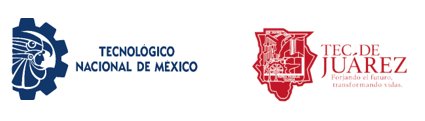


# **Analítica de Datos – Unidad 2 · Práctica 1**
### *Análisis* exploratorio y visualización: Forbes 2000 Top Companies

**Integrantes del equipo:**
*   Delgado Ramírez María Fernanda
*   Esquivel Torres Jose Enrique
*   Llanas Hernández Mia


**Contenido de la práctica:** gráficas de barras, de caja/bigote, de dispersión y de calor.

**Contenido del notebook**
1. Configuración y carga de datos
2. Exploración del dataframe
3. Estadística descriptiva y agrupamientos
4. Histogramas
5. Gráficas de barras
6. Gráfica de caja (boxplot)
7. Gráficas de dispersión
8. Gráfica de calor
9. Conclusiones

## 1. Configuración y carga de datos

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Librerías
import pandas as pd
import numpy as np
# matplotlib (para gráficas, colores, etc.)
import matplotlib.pyplot as plt
# seaborn (gráficas estadísticas)
import seaborn as sns

En esta actividad se usa el archivo de datos `Forbes_2000_top_company.csv`. Este conjunto contiene las 2000 principales empresas, clasificadas mediante el uso de cuatro métricas: ventas, ganancias, activos y valor de mercado. Tiene 11 columnas de datos:

*   `2022 Ranking`: Ranking del año actual de la empresa
*   `Organization Name`: Nombre
*   `Industry`: El tipo de industria con la que trata principalmente
*   `Country`: País de origen
*   `Year Founded`: Año en que se fundó
*   `CEO`: CEO
*   `Revenue (Billions)`: Ingresos del año
*   `Profits (Billions)`: Ganancias del año
*   `Assets (Billions)`: Activos del año
*   `Market Value (Billions)`: Valor de mercado del año
*   `Total Employees`: Total de empleados

Fuente: https://www.kaggle.com/datasets/ash316/forbes-top-2000-companies

Se guardan todos los registros del archivo en un dataframe llamado `forbes_df`.

In [ ]:
# Ruta del archivo en Google Drive. Cada integrante debe dejar activa SU ruta:
RUTA_CSV = '/content/drive/MyDrive/Colab Notebooks/Analisis/Forbes_2000_top_company.csv'      # Delgado
# RUTA_CSV = '/content/drive/MyDrive/Análitica de Datos /Forbes_2000_top_company.csv'         # Llanas
# RUTA_CSV = '/content/drive/MyDrive/T-Escuela_8/Inteligencia Artifical/Python/U1/Ejercicio 1/Forbes_2000_top_company.csv'  # Esquivel

forbes_df = pd.read_csv(RUTA_CSV)
forbes_df

,2022 Ranking,Organization Name,Industry,Country,Year Founded,CEO,Revenue (Billions),Profits (Billions),Assets (Billions),Market Value (Billions),Total Employees
0,1,Berkshire Hathaway,Diversified Financials,United States,1939,Warren Edward Buffett,276.09,89.80,958.78,741.48,372000
1,2,ICBC,Banking,China,1984,Shu Gu,208.13,54.03,5518.51,214.42,449296
2,3,Saudi Arabian Oil Company (Saudi Aramco),Oil & Gas Operations,Saudi Arabia,1933,Amin bin Hasan Al-Nasser,400.38,105.36,576.04,2292.08,68493
3,4,JPMorgan Chase,Diversified Financials,United States,2000,Jamie Dimon,124.54,42.12,3954.69,374.45,271025
4,5,China Construction Bank,Banking,China,2014,Wang Zuji,202.07,46.89,4746.95,181.32,352621
...,...,...,...,...,...,...,...,...,...,...,...
1994,1995,Aperam,Materials,Luxembourg,2010,Timoteo di Maulo,6.03,1.14,6.72,3.16,0
1995,1995,Shenzhen Feima International Supply Chain,Business Services & Supplies,China,1998,Shan Min Huang,0.04,1.41,0.17,1.14,306
1996,1997,NMDC,Materials,India,1958,Sumit Deb,3.52,1.41,5.72,6.40,16944
1997,1997,Sichuan Changhong Electric,Consumer Durables,China,1988,Wei Li,15.72,0.05,12.10,1.96,51841


## 2. Exploración del dataframe

### 2.1 Estructura general

In [ ]:
# Dimensionalidad del dataframe
forbes_df.shape

(1999, 11)

In [ ]:
# Identificadores de columnas
forbes_df.columns

Index(['2022 Ranking', 'Organization Name', 'Industry', 'Country',
       'Year Founded', 'CEO', 'Revenue (Billions)', 'Profits (Billions)',
       'Assets (Billions)', 'Market Value (Billions)', 'Total Employees'],
      dtype='object')

In [ ]:
# Identificadores de registros (filas)
forbes_df.index

RangeIndex(start=0, stop=1999, step=1)

In [ ]:
# Tipos de datos
forbes_df.dtypes

,0
2022 Ranking,int64
Organization Name,object
Industry,object
Country,object
Year Founded,int64
CEO,object
Revenue (Billions),float64
Profits (Billions),float64
Assets (Billions),float64
Market Value (Billions),float64


In [ ]:
# Primeros tres registros
forbes_df.head(3)

,2022 Ranking,Organization Name,Industry,Country,Year Founded,CEO,Revenue (Billions),Profits (Billions),Assets (Billions),Market Value (Billions),Total Employees
0,1,Berkshire Hathaway,Diversified Financials,United States,1939,Warren Edward Buffett,276.09,89.80,958.78,741.48,372000
1,2,ICBC,Banking,China,1984,Shu Gu,208.13,54.03,5518.51,214.42,449296
2,3,Saudi Arabian Oil Company (Saudi Aramco),Oil & Gas Operations,Saudi Arabia,1933,Amin bin Hasan Al-Nasser,400.38,105.36,576.04,2292.08,68493


In [ ]:
# últimos 3 registros
forbes_df.tail(3)

,2022 Ranking,Organization Name,Industry,Country,Year Founded,CEO,Revenue (Billions),Profits (Billions),Assets (Billions),Market Value (Billions),Total Employees
1996,1997,NMDC,Materials,India,1958,Sumit Deb,3.52,1.41,5.72,6.40,16944
1997,1997,Sichuan Changhong Electric,Consumer Durables,China,1988,Wei Li,15.72,0.05,12.10,1.96,51841
1998,1999,Satellite Chemical,Chemicals,China,0,No Data,4.41,0.93,7.64,9.52,3409


### 2.2 Columnas numéricas y de texto

Filtrar por tipo de dato sirve para saber qué columnas se pueden usar luego en las gráficas.

In [ ]:
#Columnas de tipo numericas
#Filtramos por valores para utilizarlos luego y saber cuales pueden servirnos
forbes_df.select_dtypes(include=['number']).sort_values('Assets (Billions)', ascending=False)

,2022 Ranking,Year Founded,Revenue (Billions),Profits (Billions),Assets (Billions),Market Value (Billions),Total Employees
1,2,1984,208.13,54.03,5518.51,214.42,449296
4,5,2014,202.07,46.89,4746.95,181.32,352621
7,8,1979,181.42,37.38,4561.05,133.38,455174
337,338,1938,100.33,22.18,4229.90,0.88,7400
12,13,1929,152.43,33.57,4192.84,117.82,306322
...,...,...,...,...,...,...,...
1574,1575,0,41.81,-1.57,1.62,1.21,36992
1904,1905,1993,17.64,0.04,1.54,0.56,0
1942,1943,0,0.00,1.50,1.36,2.43,0
1745,1746,2005,0.35,0.08,0.50,34.74,517


In [ ]:
#Columnas de tipo texto
#Filtramos por texto para utilizarlos luego y saber cuales pueden servirnos
forbes_df.select_dtypes(include=['object','string'])

,Organization Name,Industry,Country,CEO
0,Berkshire Hathaway,Diversified Financials,United States,Warren Edward Buffett
1,ICBC,Banking,China,Shu Gu
2,Saudi Arabian Oil Company (Saudi Aramco),Oil & Gas Operations,Saudi Arabia,Amin bin Hasan Al-Nasser
3,JPMorgan Chase,Diversified Financials,United States,Jamie Dimon
4,China Construction Bank,Banking,China,Wang Zuji
...,...,...,...,...
1994,Aperam,Materials,Luxembourg,Timoteo di Maulo
1995,Shenzhen Feima International Supply Chain,Business Services & Supplies,China,Shan Min Huang
1996,NMDC,Materials,India,Sumit Deb
1997,Sichuan Changhong Electric,Consumer Durables,China,Wei Li


### 2.3 Índice del dataframe

In [ ]:
# Cambiando el índice del dataframe. El inplace indica que el cambio se guardará en el dataframe
forbes_df.set_index('2022 Ranking', inplace=True)
forbes_df

,Organization Name,Industry,Country,Year Founded,CEO,Revenue (Billions),Profits (Billions),Assets (Billions),Market Value (Billions),Total Employees
2022 Ranking,,,,,,,,,,
1,Berkshire Hathaway,Diversified Financials,United States,1939,Warren Edward Buffett,276.09,89.80,958.78,741.48,372000
2,ICBC,Banking,China,1984,Shu Gu,208.13,54.03,5518.51,214.42,449296
3,Saudi Arabian Oil Company (Saudi Aramco),Oil & Gas Operations,Saudi Arabia,1933,Amin bin Hasan Al-Nasser,400.38,105.36,576.04,2292.08,68493
4,JPMorgan Chase,Diversified Financials,United States,2000,Jamie Dimon,124.54,42.12,3954.69,374.45,271025
5,China Construction Bank,Banking,China,2014,Wang Zuji,202.07,46.89,4746.95,181.32,352621
...,...,...,...,...,...,...,...,...,...,...
1995,Aperam,Materials,Luxembourg,2010,Timoteo di Maulo,6.03,1.14,6.72,3.16,0
1995,Shenzhen Feima International Supply Chain,Business Services & Supplies,China,1998,Shan Min Huang,0.04,1.41,0.17,1.14,306
1997,NMDC,Materials,India,1958,Sumit Deb,3.52,1.41,5.72,6.40,16944


In [ ]:
# Ya no se puede hacer referencia a la columna como forbes_df['2022 Ranking'] porque ya es índice del dataframe, ahora se debe usar forbes_df.index
forbes_df.index

Index([   1,    2,    3,    4,    5,    6,    7,    8,    9,   10,
       ...
       1989, 1991, 1992, 1993, 1993, 1995, 1995, 1997, 1997, 1999],
      dtype='int64', name='2022 Ranking', length=1999)

### 2.4 Valores únicos, frecuencias y ordenamiento

In [ ]:
# Cantidad de valores únicos por columna
forbes_df.nunique()

,0
Organization Name,1999
Industry,29
Country,57
Year Founded,214
CEO,1963
Revenue (Billions),1587
Profits (Billions),688
Assets (Billions),1790
Market Value (Billions),1665
Total Employees,1726


In [ ]:
# Valores únicos de una columna en particular
forbes_df['Industry'].unique()

array(['Diversified Financials', 'Banking', 'Oil & Gas Operations',
       'Retailing', 'Technology Hardware & Equipment',
       'Consumer Durables', 'IT Software & Services', 'Insurance',
       'Telecommunications Services', 'Media', 'Drugs & Biotechnology',
       'Food, Drink & Tobacco', 'Semiconductors',
       'Household & Personal Products', 'Materials', 'Conglomerates',
       'Trading Companies', 'Transportation', 'Construction',
       'Aerospace & Defense', 'Utilities',
       'Health Care Equipment & Services', 'Chemicals', 'Capital Goods',
       'Business Services & Supplies', 'Hotels, Restaurants & Leisure',
       'Food Markets', 'Food & Drink', 'Automotive'], dtype=object)

In [ ]:
# Frecuencia de valores únicos de una columna en particular
forbes_df['Industry'].value_counts()

,count
Industry,
Banking,289
Diversified Financials,146
Construction,127
Materials,117
Oil & Gas Operations,106
Insurance,105
Consumer Durables,89
Utilities,83
Business Services & Supplies,82


In [ ]:
# Con normalize=True se obtiene el porcentaje
forbes_df['Industry'].value_counts(normalize=True)

,proportion
Industry,
Banking,0.144572
Diversified Financials,0.073037
Construction,0.063532
Materials,0.058529
Oil & Gas Operations,0.053027
Insurance,0.052526
Consumer Durables,0.044522
Utilities,0.041521
Business Services & Supplies,0.041021


In [ ]:
# Podemos hacer slicing del resultado (primeros 5 registros)
forbes_df['Country'].value_counts()[:5]

,count
Country,
United States,584
China,297
Japan,196
South Korea,65
United Kingdom,64


In [ ]:
# Podemos hacer slicing del resultado (últimos 5 registros)
forbes_df['Country'].value_counts()[-5:]

,count
Country,
Uruguay,1
Cayman Islands,1
Argentina,1
Egypt,1
Nigeria,1


In [ ]:
# Para ordenar por la columna especificada
forbes_df.sort_values('Year Founded', ascending=False)

,Organization Name,Industry,Country,Year Founded,CEO,Revenue (Billions),Profits (Billions),Assets (Billions),Market Value (Billions),Total Employees
2022 Ranking,,,,,,,,,,
613,Warner Bros. Discovery,Media,United States,2022,David M. Zaslav,12.18,1.02,34.43,49.92,11000
79,Stellantis,Consumer Durables,Netherlands,2021,Carlos Tavares,176.61,16.78,195.33,44.26,281595
109,Raytheon Technologies,Aerospace & Defense,United States,2020,Gregory J. Hayes,64.36,3.86,161.40,149.76,174000
1579,Royalty Pharma,Drugs & Biotechnology,United States,2020,Pablo Gerardo Legorreta,2.29,0.62,17.52,18.48,66
458,Corteva,Chemicals,United States,2019,Chuck Magro,15.66,1.76,42.34,41.92,21000
...,...,...,...,...,...,...,...,...,...,...
1418,Xiamen International Trade Group,Trading Companies,China,0,Shao Yong Gao,72.02,0.48,15.34,2.54,5504
1419,China Grand Automotive Services,Retailing,China,0,Xin Ming Wang,26.26,0.28,20.10,2.79,43902
1334,NARI Technology Development,Capital Goods,China,0,Zong Qiang Zheng,6.36,0.84,10.68,22.89,8806


In [ ]:
# Como no se incluyó el parámetro inplace=True en el ordenamiento, los cambios NO se guardan
forbes_df

,Organization Name,Industry,Country,Year Founded,CEO,Revenue (Billions),Profits (Billions),Assets (Billions),Market Value (Billions),Total Employees
2022 Ranking,,,,,,,,,,
1,Berkshire Hathaway,Diversified Financials,United States,1939,Warren Edward Buffett,276.09,89.80,958.78,741.48,372000
2,ICBC,Banking,China,1984,Shu Gu,208.13,54.03,5518.51,214.42,449296
3,Saudi Arabian Oil Company (Saudi Aramco),Oil & Gas Operations,Saudi Arabia,1933,Amin bin Hasan Al-Nasser,400.38,105.36,576.04,2292.08,68493
4,JPMorgan Chase,Diversified Financials,United States,2000,Jamie Dimon,124.54,42.12,3954.69,374.45,271025
5,China Construction Bank,Banking,China,2014,Wang Zuji,202.07,46.89,4746.95,181.32,352621
...,...,...,...,...,...,...,...,...,...,...
1995,Aperam,Materials,Luxembourg,2010,Timoteo di Maulo,6.03,1.14,6.72,3.16,0
1995,Shenzhen Feima International Supply Chain,Business Services & Supplies,China,1998,Shan Min Huang,0.04,1.41,0.17,1.14,306
1997,NMDC,Materials,India,1958,Sumit Deb,3.52,1.41,5.72,6.40,16944


### 2.5 Valores faltantes

In [ ]:
# Valores faltantes del dataframe (celdas que no tienen info) Se representan en pandas como NaN (Not A Number)
# En este dataframe no hay celdas sin info en ninguna columna
forbes_df.isna().sum()

,0
Organization Name,0
Industry,0
Country,0
Year Founded,0
CEO,0
Revenue (Billions),0
Profits (Billions),0
Assets (Billions),0
Market Value (Billions),0
Total Employees,0


## 3. Estadística descriptiva y agrupamientos

### 3.1 Estadísticas y filtrado

In [ ]:
# Aplicando estadísticas descriptivas en una columna
forbes_df['Profits (Billions)'].max()

105.36

In [ ]:
# Filtrando información en el dataframe con una condición
forbes_df[forbes_df['Profits (Billions)'] == forbes_df['Profits (Billions)'].max()]

,Organization Name,Industry,Country,Year Founded,CEO,Revenue (Billions),Profits (Billions),Assets (Billions),Market Value (Billions),Total Employees
2022 Ranking,,,,,,,,,,
3,Saudi Arabian Oil Company (Saudi Aramco),Oil & Gas Operations,Saudi Arabia,1933,Amin bin Hasan Al-Nasser,400.38,105.36,576.04,2292.08,68493


In [ ]:
# Otra forma de hacerlo
# La función idxmax() devuelve el índice del registro con el valor máximo de Profits (Billions) = 3
forbes_df.loc[forbes_df['Profits (Billions)'].idxmax()]

,3
Organization Name,Saudi Arabian Oil Company (Saudi Aramco)
Industry,Oil & Gas Operations
Country,Saudi Arabia
Year Founded,1933
CEO,Amin bin Hasan Al-Nasser
Revenue (Billions),400.38
Profits (Billions),105.36
Assets (Billions),576.04
Market Value (Billions),2292.08
Total Employees,68493


In [ ]:
# La serie anterior se puede convertir a un dataframe
forbes_df.loc[forbes_df['Profits (Billions)'].idxmax()].to_frame()

,3
Organization Name,Saudi Arabian Oil Company (Saudi Aramco)
Industry,Oil & Gas Operations
Country,Saudi Arabia
Year Founded,1933
CEO,Amin bin Hasan Al-Nasser
Revenue (Billions),400.38
Profits (Billions),105.36
Assets (Billions),576.04
Market Value (Billions),2292.08
Total Employees,68493


In [ ]:
# Con el atributo T se obtiene la transpuesta de la tabla anterior
forbes_df.loc[forbes_df['Profits (Billions)'].idxmax()].to_frame().T

,Organization Name,Industry,Country,Year Founded,CEO,Revenue (Billions),Profits (Billions),Assets (Billions),Market Value (Billions),Total Employees
3,Saudi Arabian Oil Company (Saudi Aramco),Oil & Gas Operations,Saudi Arabia,1933,Amin bin Hasan Al-Nasser,400.38,105.36,576.04,2292.08,68493


In [ ]:
# Las estadísticas descriptivas se pueden aplicar también a todo el dataframe y el cálculo se efectúa por columna
forbes_df.mean(numeric_only=True)

,0
Year Founded,1863.992496
Revenue (Billions),23.886628
Profits (Billions),2.503167
Assets (Billions),117.176013
Market Value (Billions),38.260675
Total Employees,48871.218609


In [ ]:
# El resultado indica que, en promedio, el valor de mercado se desvía de la media en 117 billones aproximadamente
forbes_df['Market Value (Billions)'].std()

117.23330138551879

In [ ]:
# El 75% de las empresas tienen ganancias iguales o menores a 2.27 billones
forbes_df['Profits (Billions)'].quantile(.75)

np.float64(2.27)

In [ ]:
# La función describe() regresa un resumen de varias estadísticas descriptivas para todas las columnas numéricas del dataframe
forbes_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Year Founded,1999.0,1863.992496,421.815723,0.00,1919.000,1971.00,1996.00,2022.00
Revenue (Billions),1999.0,23.886628,40.951362,0.00,5.600,12.17,23.73,572.75
Profits (Billions),1999.0,2.503167,6.160483,-12.05,0.590,1.06,2.27,105.36
Assets (Billions),1999.0,117.176013,363.826515,0.17,14.800,32.10,77.88,5518.51
Market Value (Billions),1999.0,38.260675,117.233301,0.14,7.335,16.64,34.72,2640.32
Total Employees,1999.0,48871.218609,98603.185213,0.00,7154.500,20507.00,51442.50,2300000.00


In [ ]:
# También se puede obtener un resumen para las variables de texto
forbes_df.describe(include='object').T

,count,unique,top,freq
Organization Name,1999,1999,Satellite Chemical,1
Industry,1999,29,Banking,289
Country,1999,57,United States,584
CEO,1999,1963,No Data,23


### 3.2 Agrupamientos con `groupby()`

In [ ]:
# Con groupby() se forman particiones o grupos, de manera que dentro de cada grupo todas las filas tengan el mismo valor en la columna especificada
# En esta caso, saca el promedio por industria para todas las columnas numéricas del dataframe
forbes_df.groupby('Industry').mean(numeric_only=True)

,Year Founded,Revenue (Billions),Profits (Billions),Assets (Billions),Market Value (Billions),Total Employees
Industry,,,,,,
Aerospace & Defense,1968.111111,27.293889,1.773333,49.955556,50.000556,70953.888889
Automotive,2013.500000,0.045000,-3.860000,15.085000,30.930000,7161.000000
Banking,1900.512111,14.133287,2.767785,390.609516,22.516228,33810.937716
Business Services & Supplies,1923.426829,12.461463,1.668659,121.980610,36.172927,41872.573171
Capital Goods,1744.474576,18.056780,1.325254,29.158814,27.682373,50124.711864
Chemicals,1821.840000,14.358000,1.646267,21.027333,21.925067,22615.280000
Conglomerates,1869.172414,23.352069,2.118276,51.668276,37.351379,76758.827586
Construction,1735.795276,22.788189,1.404331,58.032992,12.035197,44925.653543
Consumer Durables,1904.662921,38.928876,2.814157,60.011798,36.157753,84848.808989


In [ ]:
# Si estamos interesados en una columna en particular, se filtra el dataframe, antes de hacer el groupby()
forbes_df[['Assets (Billions)', 'Industry']].groupby('Industry').mean()

,Assets (Billions)
Industry,
Aerospace & Defense,49.955556
Automotive,15.085000
Banking,390.609516
Business Services & Supplies,121.980610
Capital Goods,29.158814
Chemicals,21.027333
Conglomerates,51.668276
Construction,58.032992
Consumer Durables,60.011798


In [ ]:
# Se pueden ordenar los valores resultantes del groupby()
forbes_df[['Assets (Billions)', 'Industry']].groupby('Industry').mean().sort_values('Assets (Billions)', ascending=False)

,Assets (Billions)
Industry,
Banking,390.609516
Insurance,224.384190
Diversified Financials,180.981986
Business Services & Supplies,121.980610
Telecommunications Services,90.579535
Oil & Gas Operations,73.279151
Trading Companies,71.822973
Utilities,63.647711
Consumer Durables,60.011798


In [ ]:
# Se pueden definir varios niveles de agrupamiento
forbes_df[['Assets (Billions)','Industry','Country']].groupby(['Industry','Country']).mean()

Assets (Billions)
Industry            Country                                
Aerospace & Defense Canada                       138.550000
                    China                         21.010000
                    France                        34.410000
                    Italy                         32.270000
                    Netherlands                  129.160000
...                                                     ...
Utilities           South Korea                  177.590000
                    Spain                         88.550000
                    United Arab Emirates          49.060000
                    United Kingdom                75.740000
                    United States                 62.473571

[495 rows x 1 columns]

## 4. Histogramas

<Axes: ylabel='Frequency'>

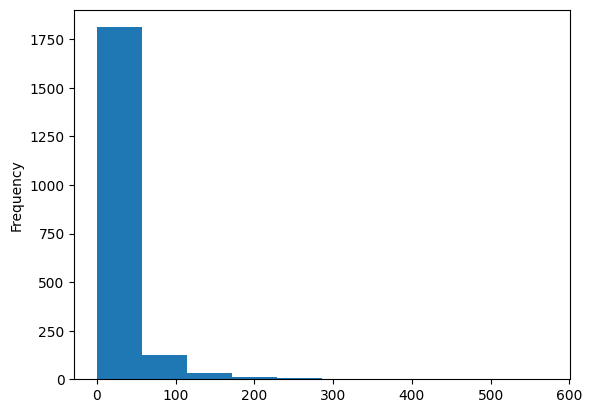

In [ ]:
# En el método plot() se especifica el tipo de gráfico a construir con el parámetro kind
# Cada columna representa una clase o bin (incluye un rango de valores)
forbes_df['Revenue (Billions)'].plot(kind='hist')

<Axes: ylabel='Frequency'>

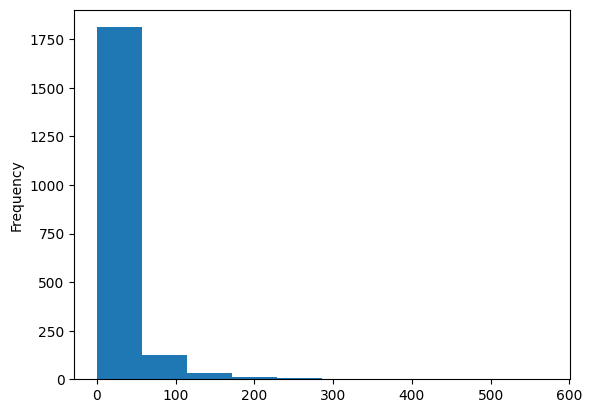

In [ ]:
# Lo anterior es equivalente a colocar el tipo de gráfico después del plot y separado por un punto
forbes_df['Revenue (Billions)'].plot.hist()

<Axes: ylabel='Frequency'>

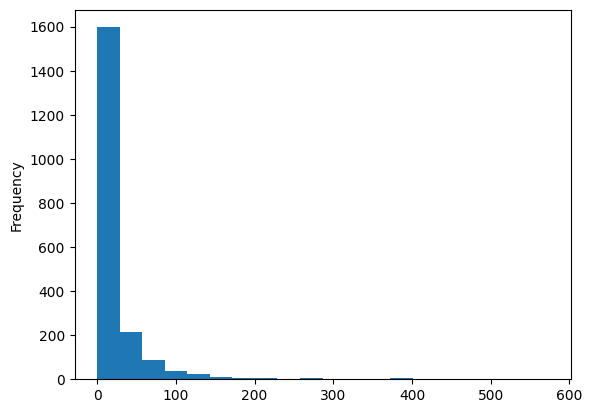

In [ ]:
# Por defecto se dibujan 10 bins, aunque en el gráfico anterior no se alcanzan a apreciar por el sesgo
# Pero este número se puede cambiar
forbes_df['Revenue (Billions)'].plot(kind='hist', bins=20)

<Axes: ylabel='Frequency'>

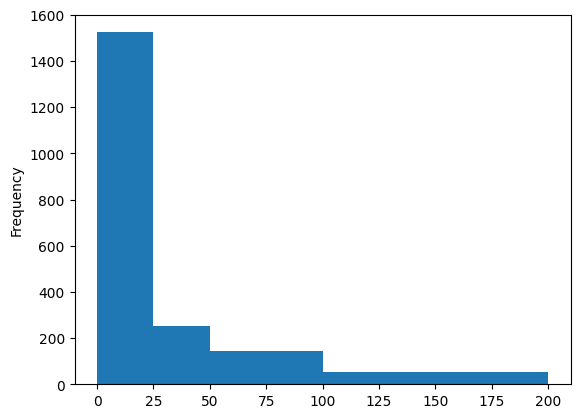

In [ ]:
# También se pueden enumerar los límites de todos los bins, sin necesidad de que sean equidistantes
forbes_df['Revenue (Billions)'].plot(kind='hist', bins=[0,25,50,100,200])

<Axes: ylabel='Frequency'>

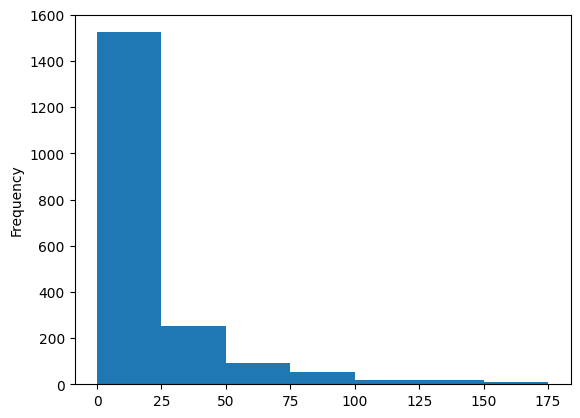

In [ ]:
# Si son equidistantes, se pueden indicar con el método arange(inicio, fin, incremento) de numpy
forbes_df['Revenue (Billions)'].plot.hist(bins=np.arange(0,200,25))

array([[<Axes: title={'center': 'Year Founded'}>,
        <Axes: title={'center': 'Revenue (Billions)'}>],
       [<Axes: title={'center': 'Profits (Billions)'}>,
        <Axes: title={'center': 'Assets (Billions)'}>],
       [<Axes: title={'center': 'Market Value (Billions)'}>,
        <Axes: title={'center': 'Total Employees'}>]], dtype=object)

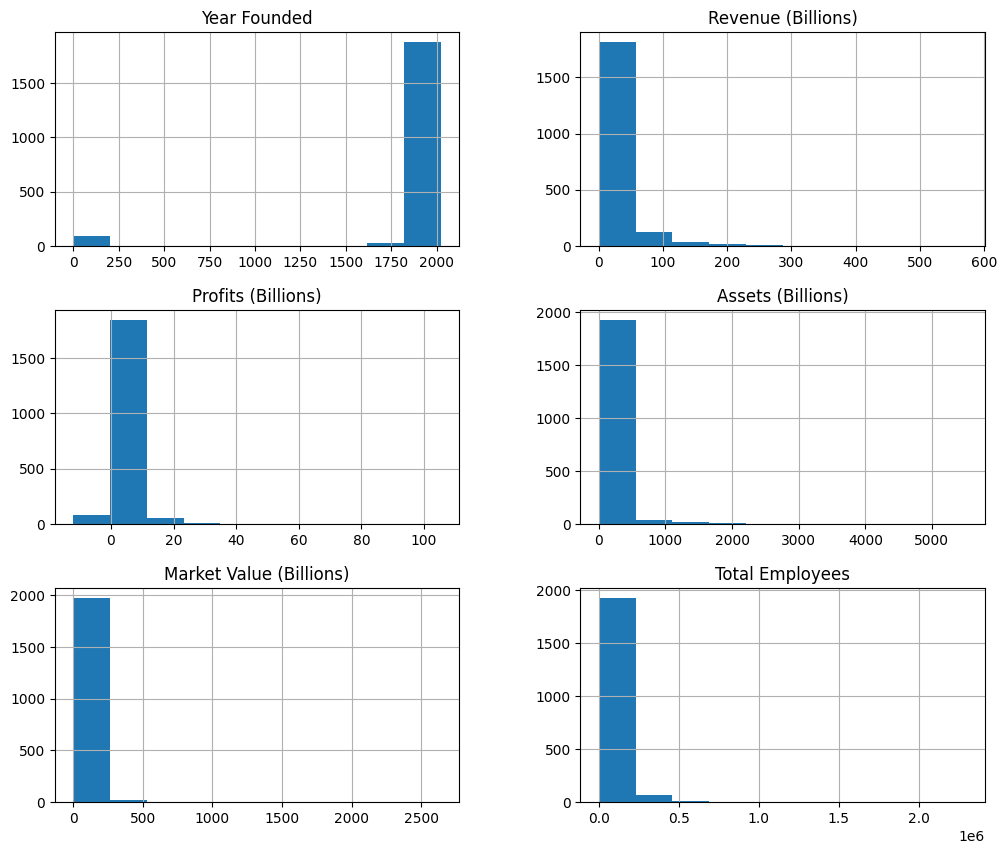

In [ ]:
# El método hist() del dataframe, obtiene un histograma para cada columna numérica
# Se puede ajustar el tamaño con figsize
forbes_df.hist(figsize=(12,10))

## 5. Gráficas de barras

Los gráficos de la sección 5.1 usan `nlargest()` para obtener los 10 mayores por cada métrica. Los de la sección 5.2 usan `head()` y `tail()`, es decir, las primeras o últimas filas del dataframe.

### 5.1 Top 10 por métrica

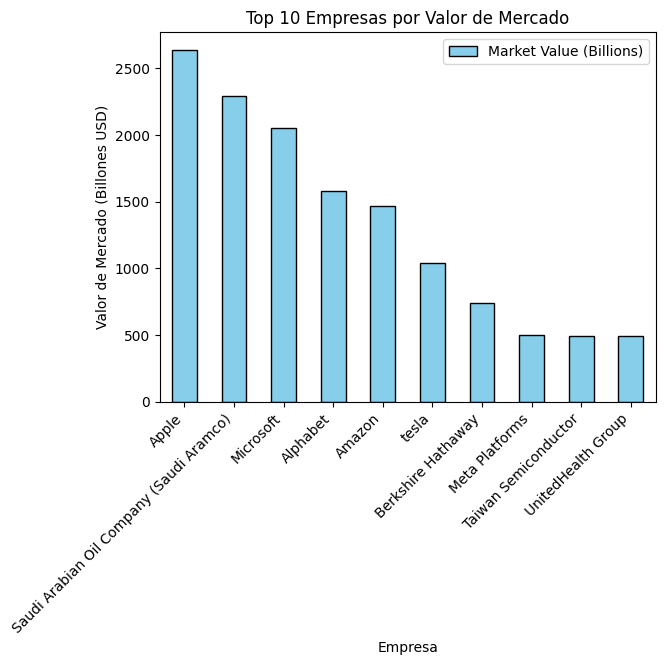

In [ ]:
# Seleccionamos las 10 empresas con mayor valor de mercado
top_empresas = forbes_df.nlargest(10, 'Market Value (Billions)')

# Creamos la gráfica de barras
top_empresas.plot(
    kind='bar',
    x='Organization Name',
    y='Market Value (Billions)',
    color='skyblue',
    edgecolor='black'
)
plt.title('Top 10 Empresas por Valor de Mercado')
plt.xlabel('Empresa')
plt.ylabel('Valor de Mercado (Billones USD)')
plt.xticks(rotation=45, ha='right')
plt.show()

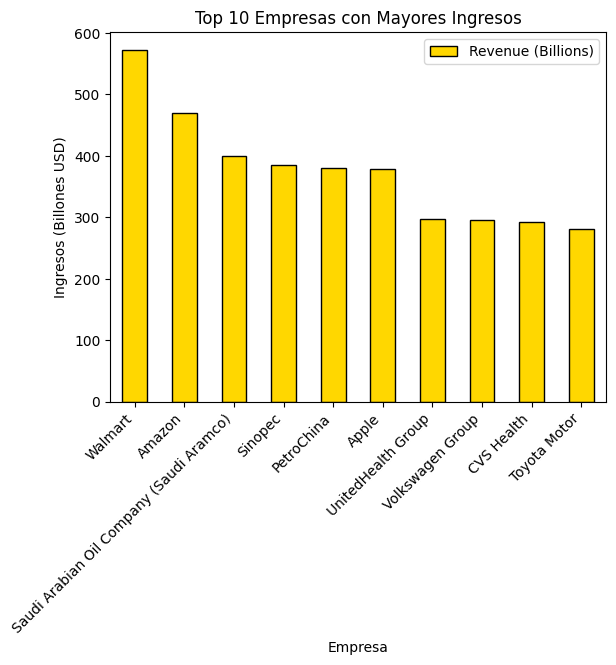

In [ ]:
# Top 10 por ingresos
top_ingresos = forbes_df.nlargest(10, 'Revenue (Billions)')

# Gráfica
top_ingresos.plot(
    kind='bar',
    x='Organization Name',
    y='Revenue (Billions)',
    color='gold',
    edgecolor='black'
)
plt.title('Top 10 Empresas con Mayores Ingresos')
plt.xlabel('Empresa')
plt.ylabel('Ingresos (Billones USD)')
plt.xticks(rotation=45, ha='right')
plt.show()

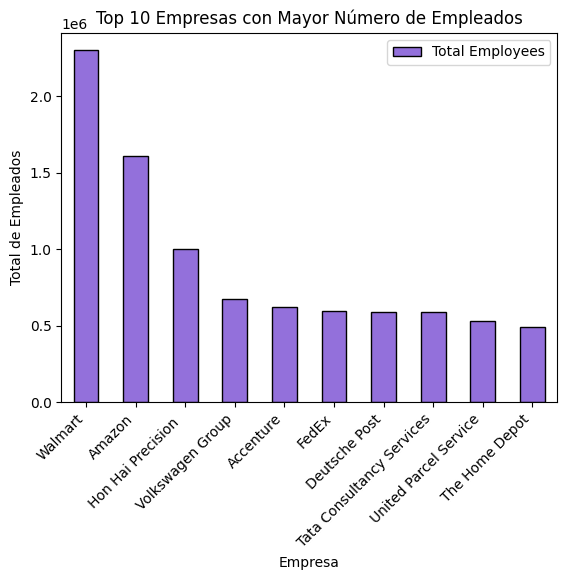

In [ ]:
# Top 10 por número de empleados
top_empleados = forbes_df.nlargest(10, 'Total Employees')

# Gráfica
top_empleados.plot(
    kind='bar',
    x='Organization Name',
    y='Total Employees',
    color='mediumpurple',
    edgecolor='black'
)
plt.title('Top 10 Empresas con Mayor Número de Empleados')
plt.xlabel('Empresa')
plt.ylabel('Total de Empleados')
plt.xticks(rotation=45, ha='right')
plt.show()

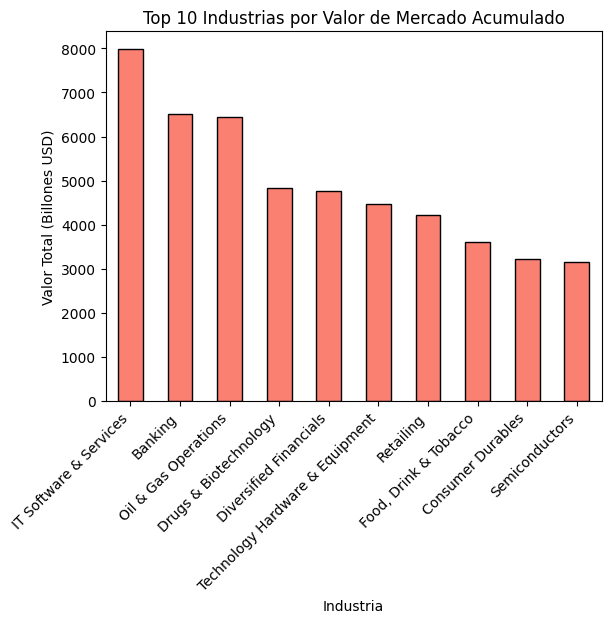

In [ ]:
# Agrupamos por industria y sumamos su valor de mercado, tomando las 10 principales
mercado_industria = (
    forbes_df.groupby('Industry')['Market Value (Billions)']
    .sum()
    .nlargest(10)
)

# Gráfica
mercado_industria.plot(kind='bar', color='salmon', edgecolor='black')
plt.title('Top 10 Industrias por Valor de Mercado Acumulado')
plt.xlabel('Industria')
plt.ylabel('Valor Total (Billones USD)')
plt.xticks(rotation=45, ha='right')
plt.show()

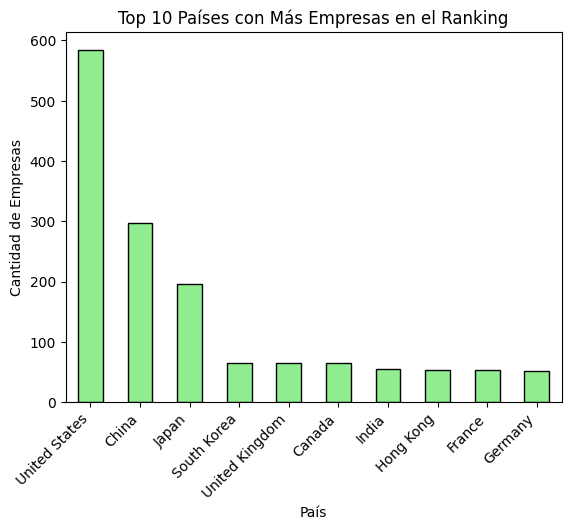

In [ ]:
# Contamos cuántas empresas hay por país y tomamos el top 10
top_paises = forbes_df['Country'].value_counts().head(10)

# Gráfica
top_paises.plot(kind='bar', color='lightgreen', edgecolor='black')
plt.title('Top 10 Países con Más Empresas en el Ranking')
plt.xlabel('País')
plt.ylabel('Cantidad de Empresas')
plt.xticks(rotation=45, ha='right')
plt.show()

### 5.2 Otras comparaciones


Text(0.5, 1.0, 'Número de empleados por organización')

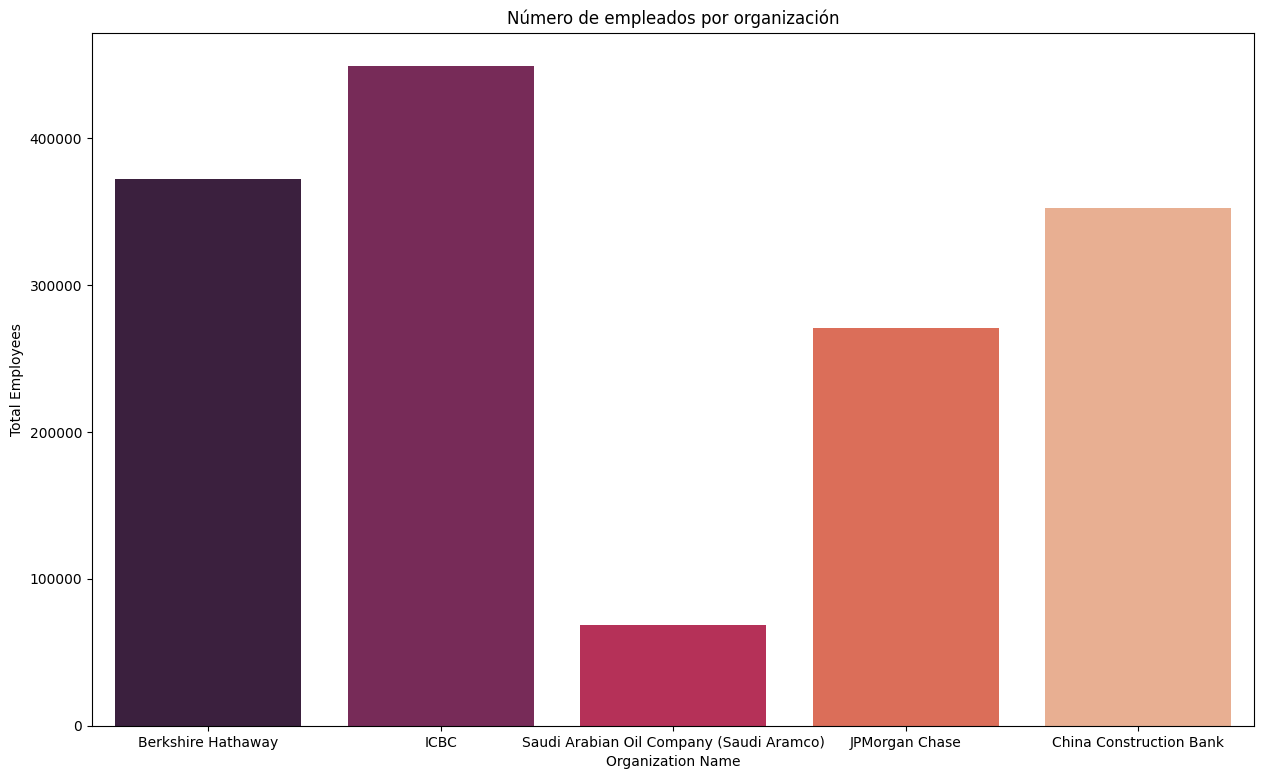

In [ ]:
plt.figure(figsize=(15,9)) #Tamaño de la gráfica
sns.barplot(data=forbes_df.head(5), x='Organization Name', y='Total Employees', palette='rocket', hue='Organization Name', legend=False)
plt.title('Número de empleados por organización')

Text(0.5, 1.0, 'Ingresos por Industria')

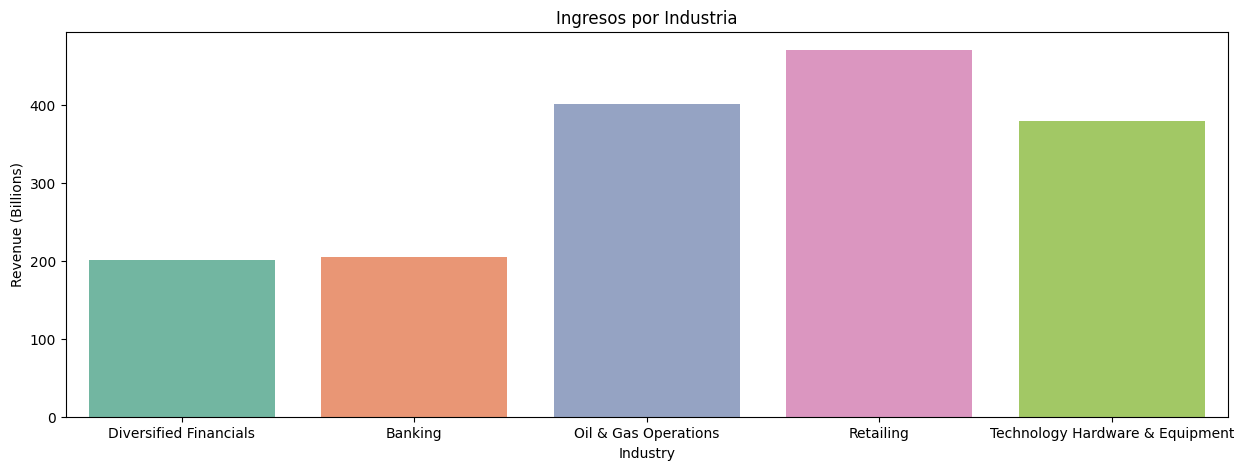

In [ ]:
plt.figure(figsize=(15,5)) #Tamaño de la gráfica
sns.barplot(data=forbes_df.head(7), x='Industry', y='Revenue (Billions)', palette='Set2', hue='Industry', errorbar=None, legend=False)
plt.title('Ingresos por Industria')

Text(0.5, 1.0, 'Beneficios por CEO')

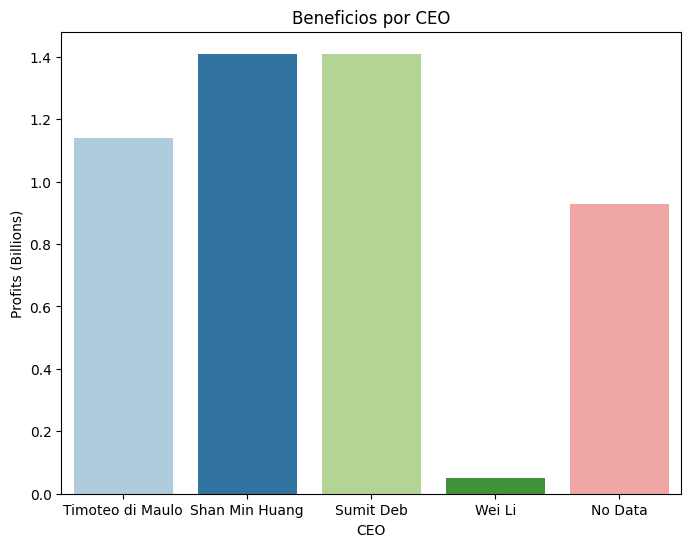

In [ ]:
plt.figure(figsize=(8,6)) #Tamaño de la gráfica
sns.barplot(data=forbes_df.tail(5), x='CEO', y='Profits (Billions)', palette='Paired', hue='CEO', errorbar=None, legend=False)
plt.title('Beneficios por CEO')

Text(0.5, 1.0, 'Activos por año de Fundación')

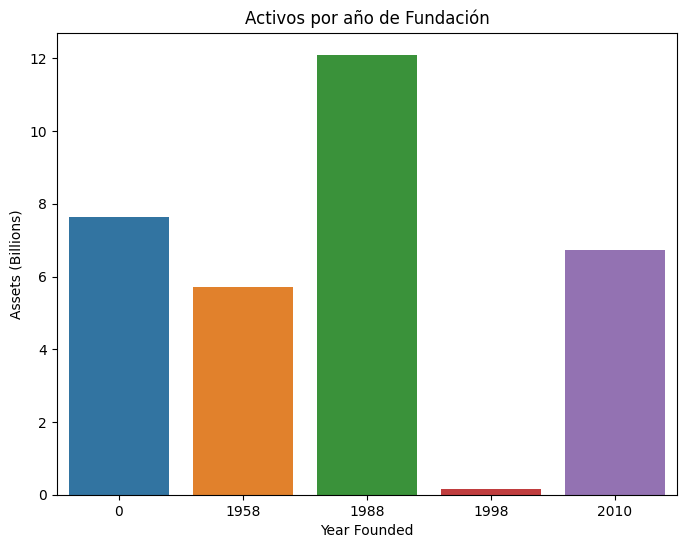

In [ ]:
plt.figure(figsize=(8,6)) #Tamaño de la gráfica
sns.barplot(data=forbes_df.tail(5), x='Year Founded', y='Assets (Billions)', palette='tab10', hue='Year Founded', errorbar=None, legend=False)
plt.title('Activos por año de Fundación')

Text(0.5, 1.0, 'Valor del mercado por País')

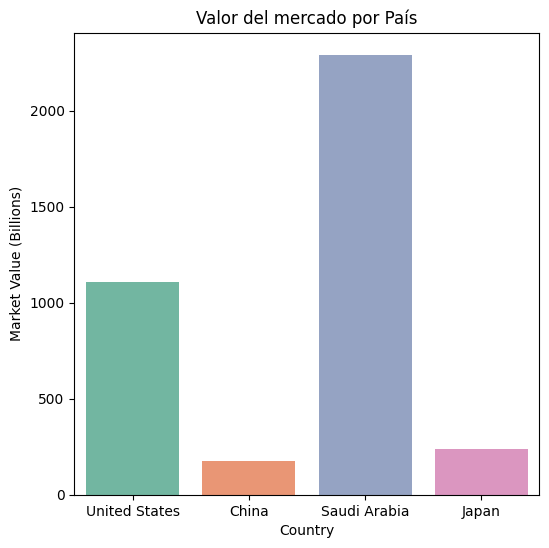

In [ ]:
plt.figure(figsize=(6,6)) #Tamaño de la gráfica
sns.barplot(data=forbes_df.head(10), x='Country', y='Market Value (Billions)', palette='Set2', hue='Country', errorbar=None, legend=False)
plt.title('Valor del mercado por País')

## 6. Gráfica de caja (boxplot)


### 6.1 Distribución del número de empleados

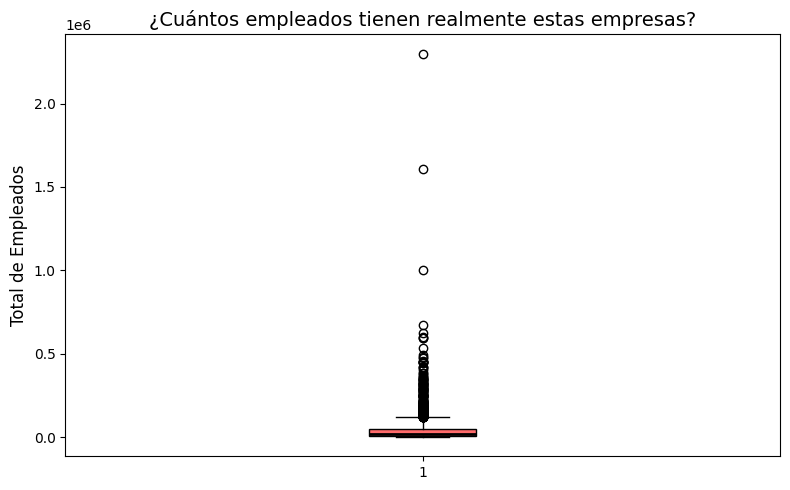

In [ ]:
plt.style.use('seaborn-v0_8-bright')
plt.figure(figsize=(8, 5))
plt.boxplot(forbes_df['Total Employees'], patch_artist=True,
            boxprops=dict(facecolor='#FF6B6B'),
            medianprops=dict(color='black', linewidth=2))
plt.title('¿Cuántos empleados tienen realmente estas empresas?', fontsize=14)
plt.ylabel('Total de Empleados', fontsize=12)
plt.tight_layout()
plt.show()
# Nota: hay unas cuantas empresas gigantes que se salen totalmente del patrón normal.

### 6.2 Activos promedio por país, agrupados por industria

Primero se calcula el promedio de activos por industria y país, y se seleccionan las 10 industrias con más registros.

In [ ]:
# 1. Tabla agrupada
tabla_agrupada = forbes_df[['Assets (Billions)', 'Industry', 'Country']].groupby(['Industry', 'Country']).mean().reset_index()

# 2. Selección de las 10 industrias principales
top_industrias = tabla_agrupada['Industry'].value_counts().head(10).index
df_grafica = tabla_agrupada[tabla_agrupada['Industry'].isin(top_industrias)]

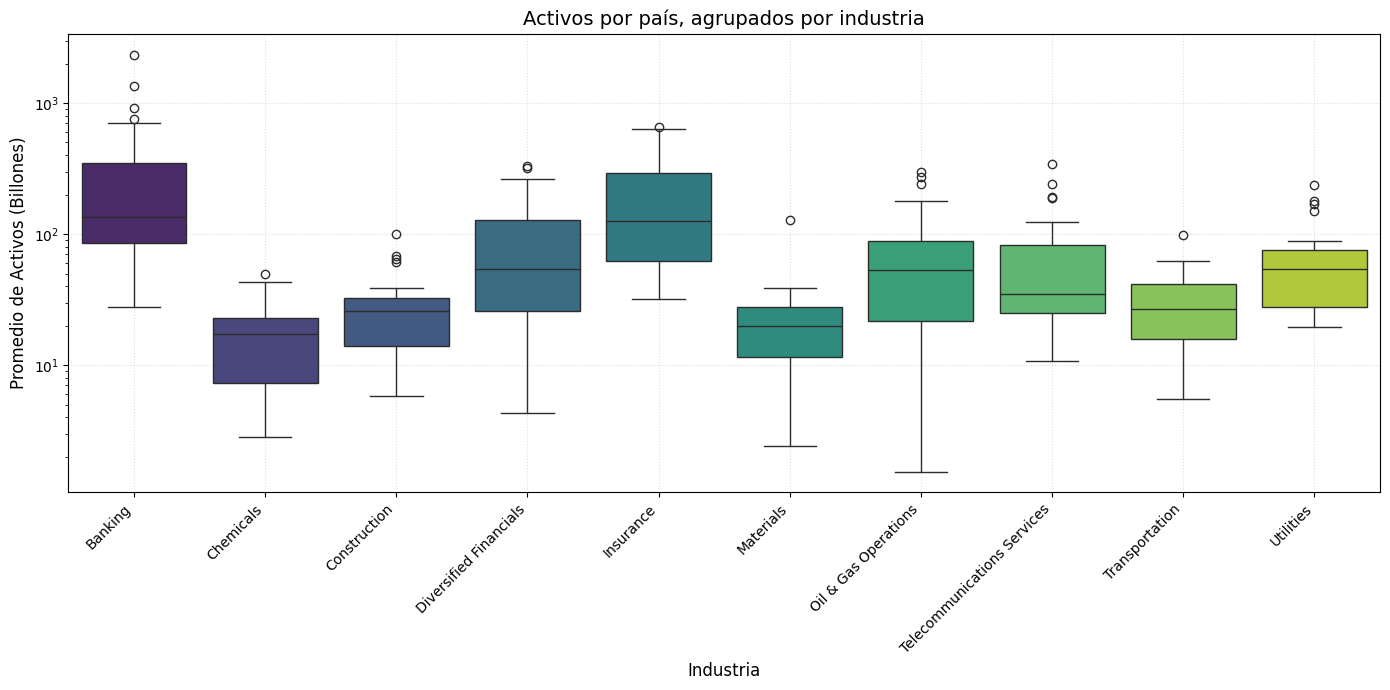

In [ ]:
plt.figure(figsize=(14, 7))
sns.boxplot(data=df_grafica, x='Industry', y='Assets (Billions)', palette='viridis', hue='Industry', legend=False)
plt.title('Activos por país, agrupados por industria', fontsize=14)
plt.xlabel('Industria', fontsize=12)
plt.ylabel('Promedio de Activos (Billones)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(True, linestyle=':', alpha=0.4)
plt.yscale('log')
plt.tight_layout()
plt.show()
# Banking se dispara arriba de todas, incluso usando escala logarítmica.

## 7. Gráficas de dispersión

### 7.1 Valor de mercado vs. activos

Primero se calculan los promedios, que se usan como límites para hacer zoom a la zona típica del mercado.

In [ ]:
print(forbes_df['Market Value (Billions)'].mean().round(2))
print(forbes_df['Assets (Billions)'].mean().round(2))

38.26
117.18


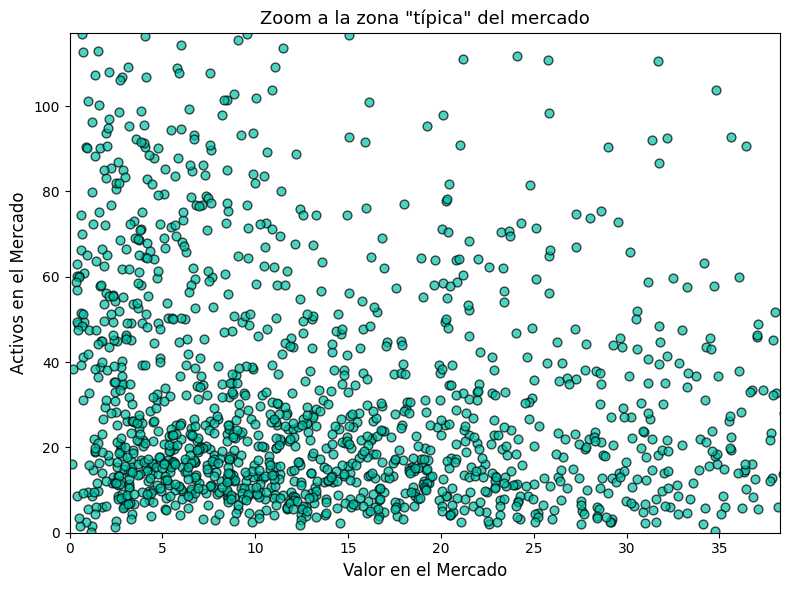

In [ ]:
valor_mercado_prom = forbes_df['Market Value (Billions)'].mean().round(2)
activos_prom = forbes_df['Assets (Billions)'].mean().round(2)

plt.figure(figsize=(8, 6))
plt.scatter(forbes_df['Market Value (Billions)'], forbes_df['Assets (Billions)'],
            color='#00C2A8', alpha=0.7, edgecolor='black', s=40)
plt.xlim(0, valor_mercado_prom)
plt.ylim(0, activos_prom)
plt.xlabel('Valor en el Mercado', fontsize=12)
plt.ylabel('Activos en el Mercado', fontsize=12)
plt.title('Zoom a la zona "típica" del mercado', fontsize=13)
plt.tight_layout()
plt.show()

Vista completa, sin limitar los ejes:

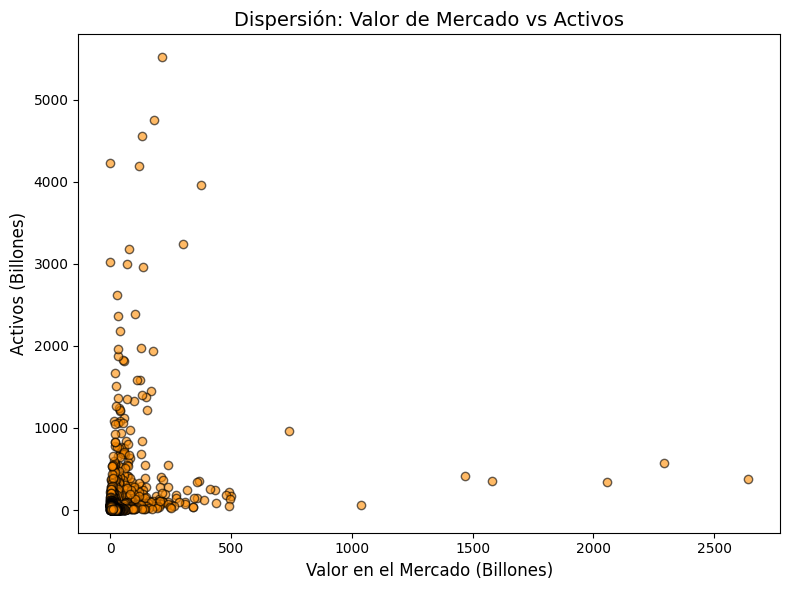

In [ ]:
# Dispersión simple con matplotlib
plt.figure(figsize=(8, 6))
plt.scatter(forbes_df['Market Value (Billions)'], forbes_df['Assets (Billions)'],
            color='darkorange', alpha=0.6, edgecolor='black')
plt.xlabel('Valor en el Mercado (Billones)', fontsize=12)
plt.ylabel('Activos (Billones)', fontsize=12)
plt.title('Dispersión: Valor de Mercado vs Activos', fontsize=14)
plt.tight_layout()
plt.show()
# Observación: se observa una relación positiva, aunque con dispersión notable
# en el rango de valores de mercado bajos.

### 7.2 Ganancias vs. valor de mercado

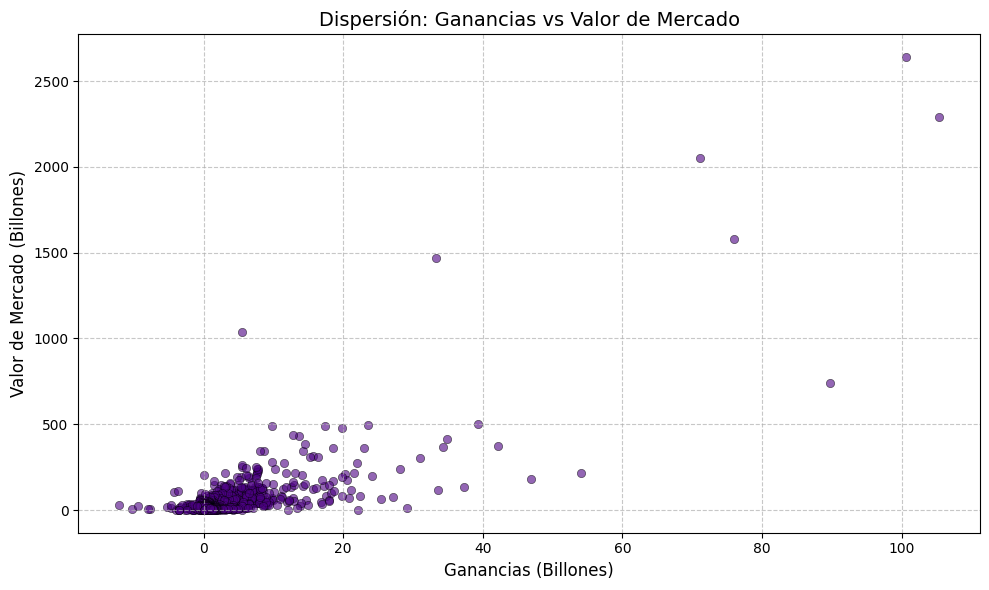

In [ ]:
# Ganancias vs Valor de Mercado
plt.figure(figsize=(10, 6))
sns.scatterplot(data=forbes_df, x='Profits (Billions)', y='Market Value (Billions)',
                 alpha=0.6, color='indigo', edgecolor='black')
plt.title('Dispersión: Ganancias vs Valor de Mercado', fontsize=14)
plt.xlabel('Ganancias (Billones)', fontsize=12)
plt.ylabel('Valor de Mercado (Billones)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
# Observación: las empresas con mayores ganancias tienden a tener un valor de
# mercado más alto, aunque con algunas excepciones notorias.

### 7.3 Ingresos vs. ganancias

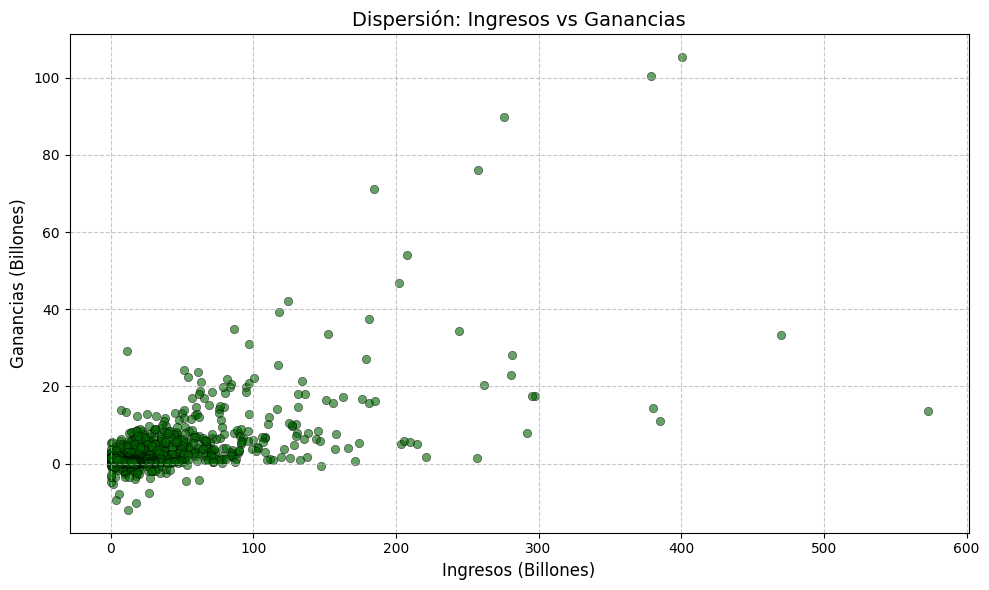

In [ ]:
# Ingresos vs Ganancias
plt.figure(figsize=(10, 6))
sns.scatterplot(data=forbes_df, x='Revenue (Billions)', y='Profits (Billions)',
                 alpha=0.6, color='darkgreen', edgecolor='black')
plt.title('Dispersión: Ingresos vs Ganancias', fontsize=14)
plt.xlabel('Ingresos (Billones)', fontsize=12)
plt.ylabel('Ganancias (Billones)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
# Observación: la relación entre ingresos y ganancias es positiva pero no lineal,
# ya que algunas empresas con ingresos altos reportan ganancias comparativamente bajas.

Mismo par de variables, con los ejes invertidos:

Text(0.5, 1.0, 'Beneficio vs Ingresos')

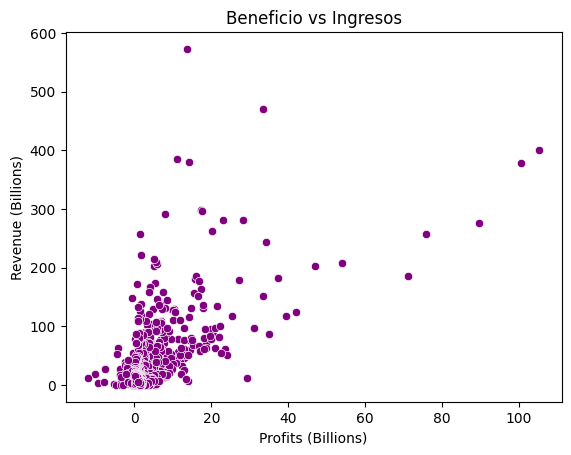

In [ ]:
sns.scatterplot(data=forbes_df, x='Profits (Billions)', y='Revenue (Billions)', color='purple')
plt.title('Beneficio vs Ingresos')

### 7.4 Año de fundación vs. ingresos

Text(0.5, 1.0, 'Año de fundación vs Ingresos')

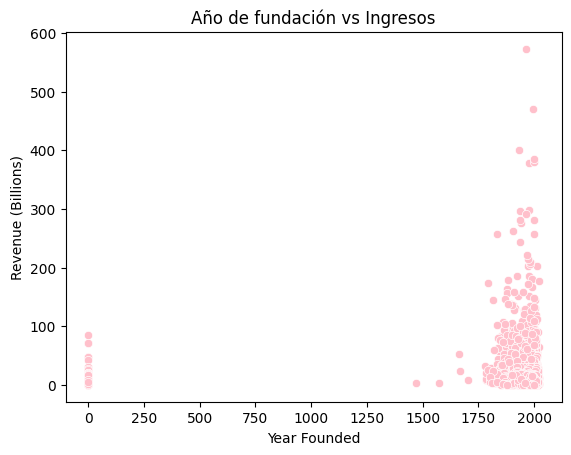

In [ ]:
sns.scatterplot(data=forbes_df, x='Year Founded', y='Revenue (Billions)', color='pink')
plt.title('Año de fundación vs Ingresos')

## 8. Gráfica de calor (correlaciones)

Como `2022 Ranking` pasó a ser el índice del dataframe (sección 2.3), la correlación se calcula solo entre las variables numéricas restantes.

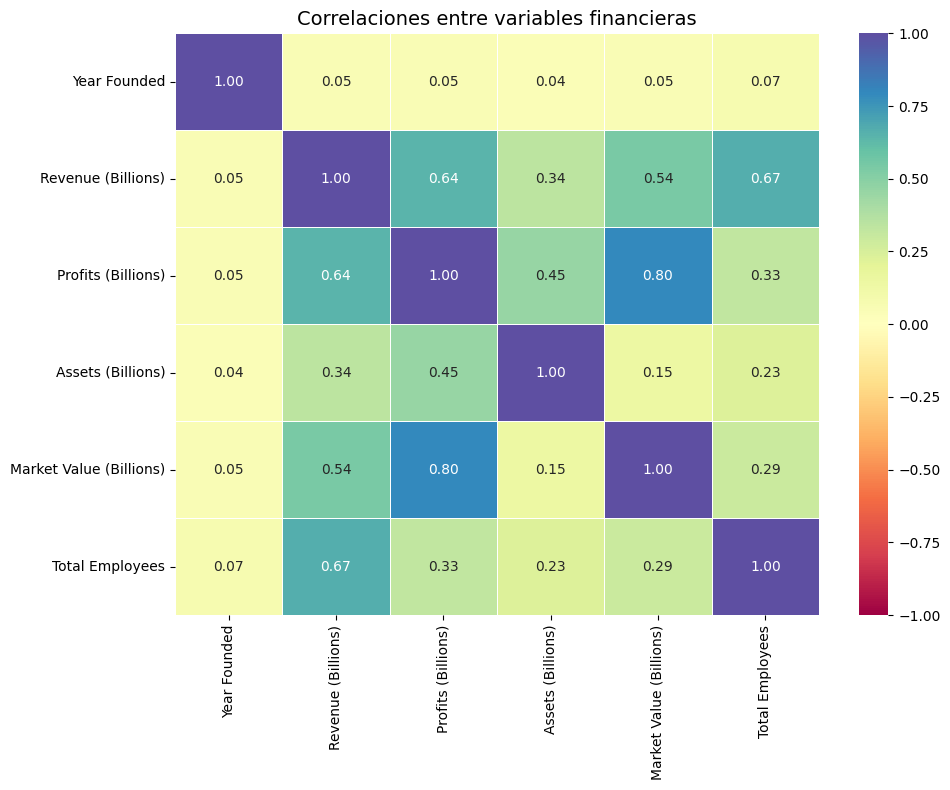

In [ ]:
plt.figure(figsize=(10, 8))
correlacion = forbes_df.corr(numeric_only=True)
sns.heatmap(correlacion, annot=True, cmap='Spectral', fmt=".2f", linewidths=0.6, vmin=-1, vmax=1)
plt.title('Correlaciones entre variables financieras', fontsize=14)
plt.tight_layout()
plt.show()
# Revenue y Profits van casi de la mano; Total Employees casi no se relaciona con nada.

## 9. Conclusiones

Del análisis de las 2000 empresas del ranking Forbes se desprende que el tamaño de una empresa no se mide igual en todas las variables. En el número de empleados hay unas cuantas compañías gigantes que se salen por completo del patrón normal y aparecen como valores atípicos en el boxplot. Algo parecido ocurre con los activos: al agruparlos por industria, el sector bancario se dispara por encima de todos los demás, incluso al usar escala logarítmica.

En cuanto a las relaciones entre variables, el valor de mercado y los activos mantienen una relación positiva, aunque con una dispersión notable cuando el valor de mercado es bajo. Las empresas con mayores ganancias tienden a tener también un mayor valor de mercado, con algunas excepciones notorias. Los ingresos y las ganancias se relacionan de forma positiva pero no lineal, ya que algunas empresas con ingresos altos reportan ganancias comparativamente bajas.

El mapa de calor confirma estas observaciones: los ingresos y las ganancias van casi de la mano, mientras que el total de empleados casi no se relaciona con ninguna otra variable.